In [37]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Pauli errors backpropagation

## Interaction trotter layer

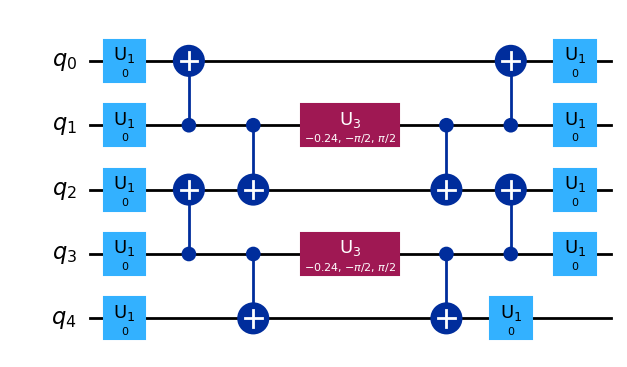

In [38]:
from z2chain.circs import string_quench_simulation_circuits_dt, string_quench_simulation_and_odr_circs
from z2chain.gdd import random, constant, counteract_rotation, zero_mean
from qiskit_addon_utils.slicing import slice_by_barriers
from functools import partial
import numpy as np

L = 3
m = 0 #np.pi/0.15
g = 0
lamb = 0.8

x_basis = False

particle_pair_left_position = 0
particle_pair_length = 1

dt = 0.15
steps = 1

# g_func = partial(counteract_rotation, ham_param=J)
# g_func = partial(constant, angle=np.pi)
# g_func = random
# g_func = partial(from_matrix, matrix=zero_mean_gdd_matrix(L, steps))
g_func = None

optimization_level = 0

circuit = string_quench_simulation_circuits_dt(L, m, g, lamb, dt*steps, dt, steps, None, optimization_level, g_func, None, None, None, x_basis, barriers=True, measure=False)[-1]
layer_slices = slice_by_barriers(circuit)

layer_slices[0].draw(output="mpl")

## Observable string length histogram

In [39]:
from qiskit.quantum_info import SparsePauliOp
from z2chain.errorprop import get_prop_obs_pauli_distribution

observable = SparsePauliOp("ZIIII")

get_prop_obs_pauli_distribution(layer_slices, observable, "Z")

([array([1, 3]), array([0.94349746, 0.05650254])],
 [array([1]), array([0.94349746])])

In [40]:
from z2chain.errorprop import propagate_error, get_error_slice, get_all_error_args, error_tup_to_obs

errors = get_all_error_args(layer_slices)

error_slice = get_error_slice(layer_slices, *errors[0][:2])
error_slice.draw()

┌───────┐┌───┐                                  ┌───┐  ┌───────┐
q_0: ┤ U1(0) ├┤ X ├──────────────────────────────────┤ X ├──┤ U1(0) ├
     ├───────┤└─┬─┘     ┌────────────────────┐       └─┬─┘  ├───────┤
q_1: ┤ U1(0) ├──■────■──┤ U3(-0.24,-π/2,π/2) ├──■──────■────┤ U1(0) ├
     ├───────┤┌───┐┌─┴─┐└────────────────────┘┌─┴─┐  ┌───┐  ├───────┤
q_2: ┤ U1(0) ├┤ X ├┤ X ├──────────────────────┤ X ├──┤ X ├──┤ U1(0) ├
     ├───────┤└─┬─┘└───┘┌────────────────────┐└───┘  └─┬─┘  ├───────┤
q_3: ┤ U1(0) ├──■────■──┤ U3(-0.24,-π/2,π/2) ├──■──────■────┤ U1(0) ├
     ├───────┤     ┌─┴─┐└────────────────────┘┌─┴─┐┌───────┐└───────┘
q_4: ┤ U1(0) ├─────┤ X ├──────────────────────┤ X ├┤ U1(0) ├─────────
     └───────┘     └───┘                      └───┘└───────┘

In [41]:
# errors = [
#     (0, 0, 0, "X"),
#     (0, 0, 0, "Z"),
#     (0, 0, 1, "X"),
#     (0, 0, 1, "Z"),
#     (0, 0, 2, "X"),
#     (0, 0, 2, "Z"),
#     (0, 2, 1, "Z"),
# ]

[propagate_error(get_error_slice(layer_slices, *error[:2]), error_tup_to_obs(get_error_slice(layer_slices, *error[:2]), error)) for error in errors]

[SparsePauliOp(['XIIII'],
               coeffs=[1.+0.j]),
 SparsePauliOp(['ZIIII', 'YXXII'],
               coeffs=[ 0.97133797+0.j, -0.23770263+0.j]),
 SparsePauliOp(['IXIII'],
               coeffs=[1.+0.j]),
 SparsePauliOp(['IZIII', 'XYXII'],
               coeffs=[ 0.97133797+0.j, -0.23770263+0.j]),
 SparsePauliOp(['IIXII'],
               coeffs=[1.+0.j]),
 SparsePauliOp(['IIZII', 'XXYII', 'IIYXX', 'XXZXX'],
               coeffs=[ 0.94349746+0.j, -0.23088959+0.j, -0.23088959+0.j, -0.05650254+0.j]),
 SparsePauliOp(['IIIXI'],
               coeffs=[1.+0.j]),
 SparsePauliOp(['IIIZI', 'IIXYX'],
               coeffs=[ 0.97133797+0.j, -0.23770263+0.j]),
 SparsePauliOp(['IIIIX'],
               coeffs=[1.+0.j]),
 SparsePauliOp(['IIIIZ', 'IIXXY'],
               coeffs=[ 0.97133797+0.j, -0.23770263+0.j]),
 SparsePauliOp(['XIIII'],
               coeffs=[1.+0.j]),
 SparsePauliOp(['ZIIII', 'YXXII'],
               coeffs=[ 0.97133797+0.j, -0.23770263+0.j]),
 SparsePauliOp(['IXIII'],
    

In [42]:
errors = [
    (0, 0, 0, "X"),
    (0, 0, 0, "Z"),
    (0, 0, 1, "X"),
    (0, 0, 1, "Z"),
    (0, 0, 2, "X"),
    (0, 0, 2, "Z"),
    (0, 2, 1, "Z"),
]

[propagate_error(get_error_slice(layer_slices, *error[:2]), error_tup_to_obs(get_error_slice(layer_slices, *error[:2]), error)) for error in errors]

[SparsePauliOp(['XIIII'],
               coeffs=[1.+0.j]),
 SparsePauliOp(['ZIIII', 'YXXII'],
               coeffs=[ 0.97133797+0.j, -0.23770263+0.j]),
 SparsePauliOp(['IXIII'],
               coeffs=[1.+0.j]),
 SparsePauliOp(['IZIII', 'XYXII'],
               coeffs=[ 0.97133797+0.j, -0.23770263+0.j]),
 SparsePauliOp(['IIXII'],
               coeffs=[1.+0.j]),
 SparsePauliOp(['IIZII', 'XXYII', 'IIYXX', 'XXZXX'],
               coeffs=[ 0.94349746+0.j, -0.23088959+0.j, -0.23088959+0.j, -0.05650254+0.j]),
 SparsePauliOp(['IZIII', 'XYXII'],
               coeffs=[ 0.97133797+0.j, -0.23770263+0.j])]

In [43]:
errors = [
    SparsePauliOp("ZIIII")
]

[propagate_error(error_slice, error) for error in errors]

[SparsePauliOp(['ZIIII', 'YXXII'],
               coeffs=[ 0.97133797+0.j, -0.23770263+0.j])]

In [45]:
errors = [
    SparsePauliOp("ZIIII"),
    SparsePauliOp("YXXII")
]

[propagate_error(error_slice, error) for error in errors]

[SparsePauliOp(['ZIIII', 'YXXII'],
               coeffs=[ 0.97133797+0.j, -0.23770263+0.j]),
 SparsePauliOp(['YXXII', 'ZIIII'],
               coeffs=[0.97133797+0.j, 0.23770263+0.j])]

In [ ]:
error_slice.draw()

┌───────┐┌───┐                                  ┌───┐  ┌───────┐
q_0: ┤ U1(0) ├┤ X ├──────────────────────────────────┤ X ├──┤ U1(0) ├
     ├───────┤└─┬─┘     ┌────────────────────┐       └─┬─┘  ├───────┤
q_1: ┤ U1(0) ├──■────■──┤ U3(-0.24,-π/2,π/2) ├──■──────■────┤ U1(0) ├
     ├───────┤     ┌─┴─┐└────────────────────┘┌─┴─┐┌───────┐└───────┘
q_2: ┤ U1(0) ├─────┤ X ├──────────────────────┤ X ├┤ U1(0) ├─────────
     └───────┘     └───┘                      └───┘└───────┘